# Eurovision: predicting the points with all features

We predict how many points one country gives another country's song in a final (`points`, 0–12), for every final from 2008 to 2026. Adding up the predicted points of a song gives a predicted scoreboard, and its first place is the predicted winner.

**We only care about the winner.** Every model is judged and chosen by one question: where on the predicted scoreboard does the real winner end up?

Steps:
1. Load `features_full.csv`, make one score per country pair, and choose the features.
2. Split into train / validation / test sets.
3. Linear regression, random forest with different parameters, lasso.
4. Find the useless features and remove them.
5. Pick the best model on the validation set and predict the test set.
6. Summary.

In [1]:
%pip install pandas numpy scikit-learn matplotlib

~/.cache/uv/builds-v0/.tmp5BAk7t/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("features_full.csv", low_memory=False)
print(df.shape)
print(df.groupby("year")["vote_type"].unique())

(27918, 35)
year
2008                    [combined]
2009                    [combined]
2010                    [combined]
2011                    [combined]
2012                    [combined]
2013                    [combined]
2014                    [combined]
2015                    [combined]
2016              [jury, televote]
2017              [televote, jury]
2018              [jury, televote]
2019              [jury, televote]
2021              [jury, televote]
2022              [jury, televote]
2023    [jury, televote, combined]
2024              [jury, televote]
2025              [jury, televote]
2026              [televote, jury]
Name: vote_type, dtype: object


## 1. One score per country pair

The voting rules changed in 2016:
- **2008–2015**: every country gives **one** set of points (jury and public already merged), `vote_type` = `combined`.
- **2016–2026**: every country gives **two** sets of points, one from the jury and one from the public.

To compare all years we take **half of jury plus public** from 2016 on. Then every year has one score per pair from 0 to 12, like before 2016, and the sum per song is exactly half of its official points. All the other columns are the same in the jury row and the public row of a pair, so we just keep the first one.

Since 2023 the viewers in countries without an entry vote together as "rest of the world" (`WLD`). That is a public vote without a jury, filed as `combined` in 2023 and as `televote` after. We treat it as a public vote in every year and halve it like any other, a missing jury counts as 0. Otherwise it would count twice as much as a country and the real scoreboard would differ from the official one (checked against the official totals: 0 differences in 462 songs, 40 before).

In [3]:
# rest of the world is a public vote, also where 2023 files it as combined
df.loc[(df["from_iso3"] == "WLD") & (df["year"] >= 2016), "vote_type"] = "televote"

keys = ["year", "from_iso3", "to_iso3"]
others = {column: "first" for column in df.columns if column not in keys + ["points"]}
df = df.groupby(keys, as_index=False).agg({"points": "sum", **others})
df["points"] = df["points"].astype(float)
# from 2016 every ballot counts half, a missing jury counts as 0
df.loc[df["year"] >= 2016, "points"] /= 2
print(df.shape)
df.head()

(18069, 35)


,year,from_iso3,to_iso3,points,censored,colony,comcol,comlang_ethno,comlang_off,contig,...,sentiment,separately_reported,smctry,televote_share,theme,vote_type,web_interest,youtube_interest,artist_age,artist_sex
0,2008,ALB,ARM,2.0,True,False,False,False,False,False,...,neutral,False,False,1.0,romance,combined,0.0,0.0,21.0,female
1,2008,ALB,AZE,0.0,True,False,False,False,False,False,...,neutral,False,False,1.0,society,combined,0.0,0.0,NaN,NaN
2,2008,ALB,BIH,0.0,True,False,False,False,False,False,...,funny,False,False,1.0,romance,combined,0.0,0.0,NaN,NaN
3,2008,ALB,DEU,0.0,True,False,False,False,False,False,...,sad,False,False,1.0,heartbreak,combined,0.0,0.0,NaN,NaN
4,2008,ALB,DNK,0.0,True,False,False,False,False,False,...,neutral,False,False,1.0,festivity,combined,0.0,0.0,25.0,male


## 2. Features

Not every column can be used. Some only identify the row, some are the same in every row, and some are **computed from the result itself**, so they would not be known before the final (using them would be cheating).

In [4]:
TARGET = "points"

# identify the row, not features
IDS = ["entry_id", "from_iso3", "to_iso3", "year"]
# jury or public, gone after taking the average above
VOTE = ["vote_type"]
# computed from the points of the final, unknown before the final
LEAKS = ["points_received_total", "points_share", "receiver_effect"]
# the same value in every row, or the same for every song of a final (voting rules)
CONSTANT = ["round", "jury_share", "televote_share", "separately_reported", "row_vote"]
# same information as log_dist
DUPLICATES = ["dist", "distw"]

NUMERIC = ["log_dist", "past_points", "past_meetings", "web_interest", "youtube_interest",
           "running_position", "artist_age"]
YES_NO = ["contig", "comlang_off", "comlang_ethno", "colony", "comcol", "smctry", "censored",
          "repetition_verse", "repetition_chorus"]
CATEGORIES = ["sentiment", "theme", "artist_sex"]

# yes/no columns as 1/0, categories as one 0/1 column per value
X = df[NUMERIC].astype(float)
for column in YES_NO:
    X[column] = df[column].map({True: 1, False: 0, "True": 1, "False": 0}).astype(float)
# bands have no sex, 2010 has no lyrics
missing = {"artist_sex": "band or unknown", "sentiment": "unknown", "theme": "unknown"}
X = pd.concat([X, pd.get_dummies(df[CATEGORIES].fillna(missing), dtype=float)], axis=1)
y = df[TARGET]

print(X.shape[1], "features:", list(X.columns))

33 features: ['log_dist', 'past_points', 'past_meetings', 'web_interest', 'youtube_interest', 'running_position', 'artist_age', 'contig', 'comlang_off', 'comlang_ethno', 'colony', 'comcol', 'smctry', 'censored', 'repetition_verse', 'repetition_chorus', 'sentiment_funny', 'sentiment_neutral', 'sentiment_sad', 'sentiment_unknown', 'theme_festivity', 'theme_folklore', 'theme_heartbreak', 'theme_kinship', 'theme_nature', 'theme_other', 'theme_romance', 'theme_society', 'theme_unknown', 'artist_sex_band or unknown', 'artist_sex_female', 'artist_sex_male', 'artist_sex_other']


## 3. Train, validation and test sets

We split **by year**, not randomly. In a random split some votes of the same final would be in the training set and others in the test set, so the model would partly know the answer. Splitting by year is also what a real prediction looks like: we know the past finals, not this one.

| set | finals | used for |
|---|---|---|
| train | 2008–2019 (11 finals, 2020 was cancelled) | fitting the models |
| validation | 2021, 2022, 2023 | choosing parameters and the best model |
| test | 2024, 2025, 2026 | the final check, used only once at the end |

Missing values are filled with the median of the **training** set. Note: 2010 has no lyrics and no Google Trends data, so for 2010 those columns are filled with the median too.

In [5]:
TRAIN = [2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019]
VAL = [2021, 2022, 2023]
TEST = [2024, 2025, 2026]

train = df["year"].isin(TRAIN)
val = df["year"].isin(VAL)
test = df["year"].isin(TEST)

medians = X[train].median()
X = X.fillna(medians)

X_train, y_train = X[train], y[train]
X_val, y_val = X[val], y[val]
X_test, y_test = X[test], y[test]
print("train / val / test rows:", len(y_train), len(y_val), len(y_test))

train / val / test rows: 12382 2925 2762


### How we measure a model
A model predicts the points of every vote. We add them up per song, which gives a predicted scoreboard, and check where the **real winner** is on it:
- **Winner's predicted place** in every final (1 = the winner was predicted correctly).
- **Average winner place** over the finals (lower is better). This is how we compare models and choose settings.
- **Top 1 / top 3**: in how many finals the real winner was predicted first, or in the top three.
- **Chance**: a random scoreboard puts the winner in the middle (about place 13 of 26) and picks the right winner in about 1 of 26 finals.

Why not predict "winner yes or no" directly? The training years have only 11 winners, far too few to learn from. Predicting the points of every vote uses about 12,000 rows, and the winner comes out of the sum.

With only three validation finals, two models often have the same average winner place. Then the one that predicts the single votes better wins the tie (higher R² on the validation votes).

In [6]:
def winner_rank(rows, predicted):
    """for every final: predicted place of the real winner"""
    board = df.loc[rows, ["year", "to_iso3", "points"]].assign(predicted=predicted)
    board = board.groupby(["year", "to_iso3"], as_index=False)[["points", "predicted"]].sum()
    places = {}
    for year, songs in board.groupby("year"):
        songs = songs.sort_values("predicted", ascending=False).reset_index(drop=True)
        real_winner = songs["points"].idxmax()
        places[year] = real_winner + 1
    return places


def winner_summary(places):
    """average place of the real winner, and how often it was first / in the top 3"""
    values = list(places.values())
    return {"mean place": float(np.mean(values)),
            "top 1": sum(p == 1 for p in values),
            "top 3": sum(p <= 3 for p in values)}


def chance(rows):
    """a random scoreboard: winner in the middle, right winner in 1 of n songs"""
    songs = df.loc[rows].groupby("year")["to_iso3"].nunique()
    return {"mean place": float(((songs + 1) / 2).mean()),
            "top 1": float((1 / songs).sum()),
            "top 3": float((3 / songs).sum())}


def report(name, model, X_tr=None, X_va=None):
    X_va = X_val if X_va is None else X_va
    places = winner_rank(val, model.predict(X_va))
    summary = winner_summary(places)
    print(name)
    print(f"\tpredicted place of the real winner: {places}")
    print(f"\taverage winner place = {summary['mean place']:.2f}, "
          f"top 1: {summary['top 1']} of {len(places)}, top 3: {summary['top 3']} of {len(places)}")
    # lower average place first, a tie goes to the model that predicts the votes better
    return (summary["mean place"], -model.score(X_va, y_val))


val_scores = {}

c = chance(val)
print(f"chance on the validation finals: winner on average at place {c['mean place']:.1f}, "
      f"right winner in {c['top 1']:.2f} of {len(VAL)} finals")

chance on the validation finals: winner on average at place 13.3, right winner in 0.12 of 3 finals


## 4. Linear regression
The features have very different scales (distance, points, 0/1 columns), so we standardise them first. The scaler is fitted on the training set only.

In [7]:
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(part) for part in (X_train, X_val, X_test))

linear = LinearRegression().fit(X_train_s, y_train)
val_scores["linear regression"] = report("Linear regression", linear, X_train_s, X_val_s)

Linear regression
	predicted place of the real winner: {2021: 4, 2022: 9, 2023: 12}
	average winner place = 8.33, top 1: 0 of 3, top 3: 0 of 3


## 5. Random forest with different parameters
We try every combination below, train on the training set and compare where each forest puts the real winners of the validation finals (like in the homework). Takes a few minutes.

In [8]:
param_grid = ParameterGrid({
    "n_estimators": [100, 300],
    "max_depth": [4, 6, 10, None],
    "min_samples_leaf": [1, 20, 100],
})

results = []
for params in param_grid:
    model = RandomForestRegressor(random_state=0, n_jobs=-1, **params).fit(X_train, y_train)
    places = winner_rank(val, model.predict(X_val))
    results.append({**params, **{str(year): place for year, place in places.items()},
                    "mean place": np.mean(list(places.values())),
                    "tie_break": -model.score(X_val, y_val)})
# lowest average winner place first, ties go to the forest that predicts the votes better
results = pd.DataFrame(results).sort_values(["mean place", "tie_break"])
print(results.drop(columns="tie_break").head(10).round(2).to_string(index=False))

 max_depth  min_samples_leaf  n_estimators  2021  2022  2023  mean place
       NaN                20           300     1     2     1        1.33
       NaN                20           100     1     2     1        1.33
       4.0               100           100     2     2     1        1.67
       4.0               100           300     2     2     1        1.67
       4.0                20           100     3     1     1        1.67
       4.0                20           300     3     1     1        1.67
       4.0                 1           100     3     1     1        1.67
       4.0                 1           300     3     1     1        1.67
      10.0                20           300     2     2     1        1.67
       6.0                20           300     3     2     1        2.00


In [9]:
best_params = results.iloc[0][["n_estimators", "max_depth", "min_samples_leaf"]].to_dict()
best_params["n_estimators"] = int(best_params["n_estimators"])
best_params["min_samples_leaf"] = int(best_params["min_samples_leaf"])
best_params["max_depth"] = None if pd.isna(best_params["max_depth"]) else int(best_params["max_depth"])
print("Best parameters:", best_params)

forest = RandomForestRegressor(random_state=0, n_jobs=-1, **best_params).fit(X_train, y_train)
val_scores["random forest"] = report("Random forest", forest)

Best parameters: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 20}


Random forest
	predicted place of the real winner: {2021: 1, 2022: 2, 2023: 1}
	average winner place = 1.33, top 1: 2 of 3, top 3: 3 of 3


## 6. Lasso
Lasso is linear regression that pushes the weights of unhelpful features to exactly zero. The penalty strength is chosen by cross-validation inside the training set, again by year (`GroupKFold`), so no final is split.

In [10]:
folds = list(GroupKFold(n_splits=3).split(X_train_s, y_train, groups=df.loc[train, "year"]))
lasso = LassoCV(cv=folds, random_state=0).fit(X_train_s, y_train)
print(f"chosen penalty alpha = {lasso.alpha_:.4f}")
val_scores["lasso"] = report("Lasso", lasso, X_train_s, X_val_s)

chosen penalty alpha = 0.0800
Lasso
	predicted place of the real winner: {2021: 5, 2022: 6, 2023: 5}
	average winner place = 5.33, top 1: 0 of 3, top 3: 0 of 3


## 7. Which features are useless?
Two views:
- **Lasso coefficient**: 0 means lasso threw the feature away.
- **Random forest importance**: how much the forest uses the feature (all importances add up to 1).

A feature is removed if **both** say it is useless: lasso set it to 0 **and** the forest gives it less than 1 % importance.

In [11]:
features = pd.DataFrame({
    "lasso_coef": lasso.coef_,
    "forest_importance": forest.feature_importances_,
}, index=X.columns).sort_values("forest_importance", ascending=False)

useless = features[(features["lasso_coef"] == 0) & (features["forest_importance"] < 0.01)].index.tolist()
keep = [f for f in X.columns if f not in useless]
print(features.round(4).to_string())
print()
print(f"removed {len(useless)} features:", useless)
print(f"kept {len(keep)} features:", keep)

                            lasso_coef  forest_importance
past_points                     1.1844             0.4453
running_position                0.2726             0.1304
log_dist                       -0.0461             0.0811
artist_age                     -0.0697             0.0681
web_interest                    0.1089             0.0584
past_meetings                  -0.0000             0.0507
theme_heartbreak                0.0289             0.0159
youtube_interest                0.0000             0.0144
artist_sex_male                 0.1578             0.0140
repetition_verse               -0.0000             0.0138
sentiment_neutral              -0.1345             0.0135
artist_sex_female              -0.0000             0.0122
theme_romance                  -0.0000             0.0114
artist_sex_other                0.0806             0.0110
artist_sex_band or unknown     -0.0000             0.0104
theme_folklore                  0.1720             0.0075
sentiment_sad 

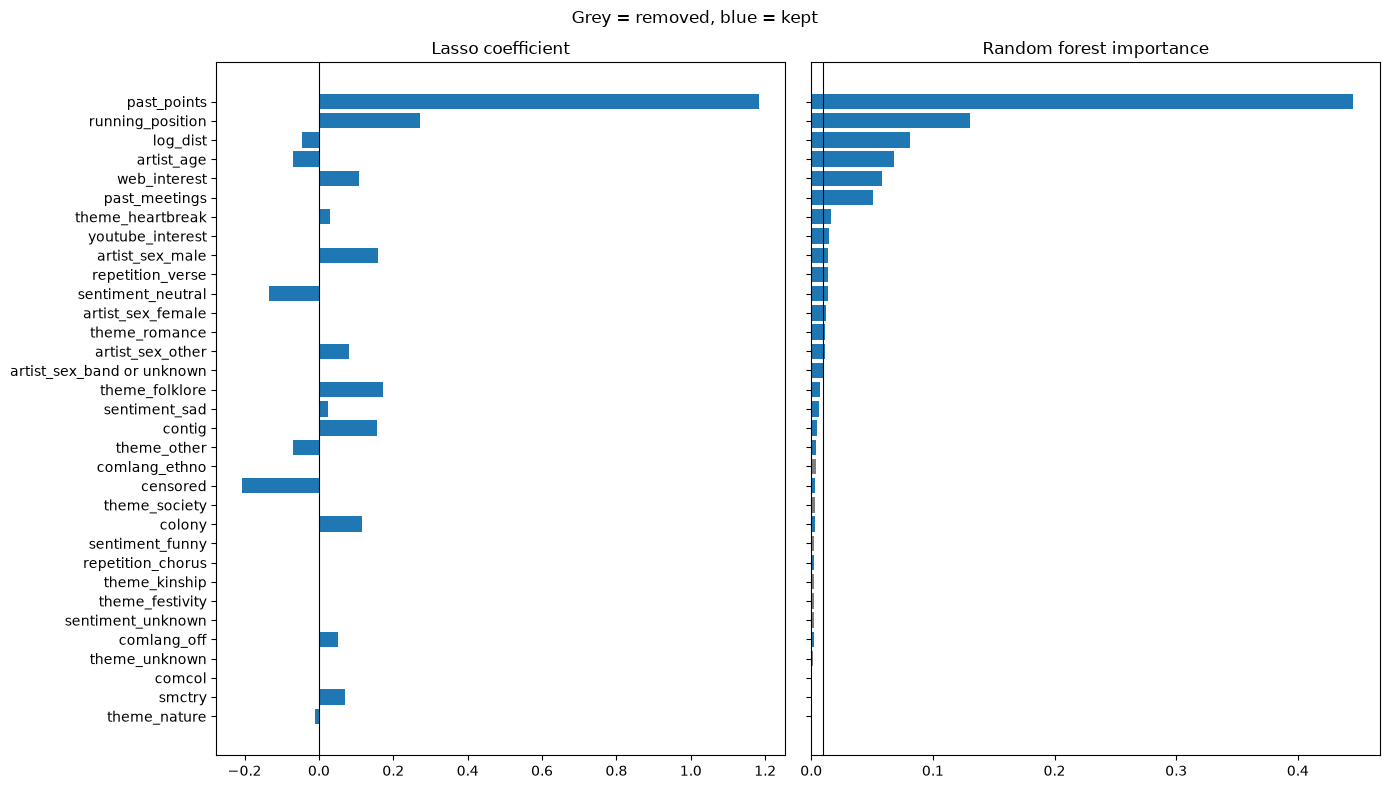

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
order = features.index[::-1]
colors = ["tab:gray" if f in useless else "tab:blue" for f in order]
axes[0].barh(order, features.loc[order, "lasso_coef"], color=colors)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Lasso coefficient")
axes[1].barh(order, features.loc[order, "forest_importance"], color=colors)
axes[1].axvline(0.01, color="black", linewidth=0.8)
axes[1].set_title("Random forest importance")
fig.suptitle("Grey = removed, blue = kept")
plt.tight_layout()
plt.show()

### Do age and sex help? The forest graph against lasso

The importance graph above says the forest uses `artist_age` (3 %) and `artist_sex` (2–3 %). Lasso gives them small weights (`artist_age` −0.07, `artist_sex_male` +0.16). But importance only says how often the forest **splits** on a column, not whether the prediction gets better. A forest also splits on noise, especially on a column like age that has many different values.

The fair test: train the same forest **with and without** a group of features and compare where it puts the real winners of 2021–2023. If the winner ends up higher without the group, the group did not help.

In [13]:
groups = {
    "nothing (all features)": [],
    "age and sex": [c for c in X.columns if c.startswith("artist_")],
    "Google searches": ["web_interest", "youtube_interest", "censored"],
    "lyrics": [c for c in X.columns if c.startswith(("sentiment_", "theme_", "repetition_"))],
    "running order": ["running_position"],
    "past points between the countries": ["past_points", "past_meetings"],
}
rows = []
for name, drop in groups.items():
    cols = [c for c in X.columns if c not in drop]
    model = RandomForestRegressor(random_state=0, n_jobs=2, **best_params).fit(X_train[cols], y_train)
    places = winner_rank(val, model.predict(X_val[cols]))
    rows.append({"left out": name, **{str(year): place for year, place in places.items()},
                 "mean place": np.mean(list(places.values()))})
ablation = pd.DataFrame(rows).set_index("left out")
print(ablation.round(2).to_string())

                                   2021  2022  2023  mean place
left out                                                       
nothing (all features)                1     2     1        1.33
age and sex                           1     2     2        1.67
Google searches                       2     9    18        9.67
lyrics                                1     2     1        1.33
running order                         7     1     1        3.00
past points between the countries     2     7     1        3.33


**Result:** the real winners 2021–2023 were predicted at places 1, 2 and 1 with all features (average 1.3).

- **Google searches matter most for the winner.** Without them the winners fall to places 2, 9 and 18 (average 9.7).
- **Past points between the countries and the running order** also help (average 3.3 and 3.0 without them).
- **Age and sex** make almost no difference (1.7 without them, one winner one place lower). **Lyrics** make none (1.3 with or without).

With three validation winners these are small samples: one winner moving a few places changes the average a lot.

### Do the extra years 2008–2015 help?

Same forest, trained once on 2008–2019 and once only on 2016–2019, both checked on where they put the validation winners. Google Trends is weak in the early years (2008 and 2009 almost all zero, 2010 missing), so this tests whether the extra years are worth it.

In [14]:
recent = (df.loc[train, "year"] >= 2016).to_numpy()
for name, used in [("2008-2019", np.ones(len(y_train), dtype=bool)), ("2016-2019", recent)]:
    model = RandomForestRegressor(random_state=0, n_jobs=2, **best_params).fit(X_train[used], y_train[used])
    places = winner_rank(val, model.predict(X_val))
    print(f"trained on {name}: real winner predicted at {places}, "
          f"average place {np.mean(list(places.values())):.2f}")

trained on 2008-2019: real winner predicted at {2021: 1, 2022: 2, 2023: 1}, average place 1.33


trained on 2016-2019: real winner predicted at {2021: 7, 2022: 12, 2023: 9}, average place 9.33


**Result:** the years 2008–2015 help a lot. Trained on 2008–2019, the forest put the 2021–2023 winners at places 1, 2 and 1. Trained only on 2016–2019, at 7, 12 and 9. More finals give the forest more examples of how countries vote, even though Google Trends is weak in the early years.

### The models again, without the useless features

In [15]:
forest_small = RandomForestRegressor(random_state=0, n_jobs=-1, **best_params).fit(X_train[keep], y_train)
val_scores["random forest, fewer features"] = report("Random forest, fewer features", forest_small,
                                                     X_train[keep], X_val[keep])

scaler_small = StandardScaler().fit(X_train[keep])
lasso_small = LassoCV(cv=folds, random_state=0).fit(scaler_small.transform(X_train[keep]), y_train)
val_scores["lasso, fewer features"] = report("Lasso, fewer features", lasso_small,
                                             scaler_small.transform(X_train[keep]),
                                             scaler_small.transform(X_val[keep]))

Random forest, fewer features
	predicted place of the real winner: {2021: 1, 2022: 3, 2023: 1}
	average winner place = 1.67, top 1: 2 of 3, top 3: 3 of 3
Lasso, fewer features
	predicted place of the real winner: {2021: 5, 2022: 6, 2023: 5}
	average winner place = 5.33, top 1: 0 of 3, top 3: 0 of 3


### Improving the model

Three things the checks above suggest, all decided on the validation finals only:
- **Leave out what does not help the winner**: age and sex, and the lyrics, did not bring the winner higher.
- **Gradient boosting**: builds the trees one after another, each fixing the errors of the ones before. Often better than a forest on tables like this one.
- **A forest of the same size with the smaller feature set**, so we see what the feature choice alone brings.

In [16]:
from sklearn.ensemble import HistGradientBoostingRegressor

slim = [c for c in X.columns if not c.startswith(("artist_", "sentiment_", "theme_", "repetition_"))]
print(len(slim), "features:", slim)

forest_slim = RandomForestRegressor(random_state=0, n_jobs=2, **best_params).fit(X_train[slim], y_train)
val_scores["random forest, no artist and lyrics"] = report("Random forest, no artist and lyrics",
                                                          forest_slim, X_train[slim], X_val[slim])

boost_results = []
for params in ParameterGrid({"learning_rate": [0.03, 0.1], "max_depth": [3, 5], "min_samples_leaf": [50, 200]}):
    model = HistGradientBoostingRegressor(max_iter=300, random_state=0, **params).fit(X_train[slim], y_train)
    places = winner_rank(val, model.predict(X_val[slim]))
    boost_results.append({**params, **{str(year): place for year, place in places.items()},
                          "mean place": np.mean(list(places.values())),
                          "tie_break": -model.score(X_val[slim], y_val)})
boost_results = pd.DataFrame(boost_results).sort_values(["mean place", "tie_break"])
print(boost_results.drop(columns="tie_break").round(2).to_string(index=False))

boost_params = boost_results.iloc[0][["learning_rate", "max_depth", "min_samples_leaf"]].to_dict()
boost_params["max_depth"] = int(boost_params["max_depth"])
boost_params["min_samples_leaf"] = int(boost_params["min_samples_leaf"])
boosting = HistGradientBoostingRegressor(max_iter=300, random_state=0, **boost_params).fit(X_train[slim], y_train)
val_scores["gradient boosting, no artist and lyrics"] = report("Gradient boosting, no artist and lyrics",
                                                              boosting, X_train[slim], X_val[slim])

13 features: ['log_dist', 'past_points', 'past_meetings', 'web_interest', 'youtube_interest', 'running_position', 'contig', 'comlang_off', 'comlang_ethno', 'colony', 'comcol', 'smctry', 'censored']


Random forest, no artist and lyrics
	predicted place of the real winner: {2021: 1, 2022: 1, 2023: 1}
	average winner place = 1.00, top 1: 3 of 3, top 3: 3 of 3


 learning_rate  max_depth  min_samples_leaf  2021  2022  2023  mean place
          0.03          3                50     1     1     1        1.00
          0.03          3               200     1     1     2        1.33
          0.03          5               200     1     1     2        1.33
          0.10          3               200     1     2     2        1.67
          0.03          5                50     1     2     2        1.67
          0.10          5               200     1     3     2        2.00
          0.10          3                50     1     3     2        2.00
          0.10          5                50     1     3     2        2.00
Gradient boosting, no artist and lyrics
	predicted place of the real winner: {2021: 1, 2022: 1, 2023: 1}
	average winner place = 1.00, top 1: 3 of 3, top 3: 3 of 3


## 8. The best model on the test set
We pick the model with the lowest average winner place on the validation finals (a tie goes to the model that predicts the votes better). Only now do we look at the test set, once.

In [17]:
ranking = sorted(val_scores.items(), key=lambda item: item[1])
print(pd.Series({name: score[0] for name, score in ranking}, name="average winner place").round(2).to_string())
best_name = ranking[0][0]
print("\nbest model:", best_name)

gradient boosting, no artist and lyrics    1.00
random forest, no artist and lyrics        1.00
random forest                              1.33
random forest, fewer features              1.67
lasso                                      5.33
lasso, fewer features                      5.33
linear regression                          8.33

best model: gradient boosting, no artist and lyrics


In [18]:
# the best model and the data it needs
best = {
    "linear regression": (linear, X_train_s, X_test_s),
    "random forest": (forest, X_train, X_test),
    "lasso": (lasso, X_train_s, X_test_s),
    "random forest, fewer features": (forest_small, X_train[keep], X_test[keep]),
    "lasso, fewer features": (lasso_small, scaler_small.transform(X_train[keep]),
                              scaler_small.transform(X_test[keep])),
    "random forest, no artist and lyrics": (forest_slim, X_train[slim], X_test[slim]),
    "gradient boosting, no artist and lyrics": (boosting, X_train[slim], X_test[slim]),
}
model, X_tr, X_te = best[best_name]
test_pred = model.predict(X_te)

test_places = winner_rank(test, test_pred)
summary = winner_summary(test_places)
c = chance(test)
print(best_name)
print(f"\tpredicted place of the real winner: {test_places}")
print(f"\taverage winner place = {summary['mean place']:.2f}, "
      f"top 1: {summary['top 1']} of {len(TEST)}, top 3: {summary['top 3']} of {len(TEST)}")
print(f"chance: winner on average at place {c['mean place']:.1f}, right winner in {c['top 1']:.2f} of {len(TEST)} finals")

gradient boosting, no artist and lyrics
	predicted place of the real winner: {2024: 1, 2025: 3, 2026: 3}
	average winner place = 2.33, top 1: 1 of 3, top 3: 3 of 3
chance: winner on average at place 13.2, right winner in 0.12 of 3 finals


In [19]:
# predicted against real top 10 of every test final
board = df.loc[test, ["year", "to_iso3", "points"]].assign(predicted=test_pred)
board = board.groupby(["year", "to_iso3"], as_index=False)[["points", "predicted"]].sum()
board["real place"] = board.groupby("year")["points"].rank(ascending=False, method="min").astype(int)
board["predicted place"] = board.groupby("year")["predicted"].rank(ascending=False, method="first").astype(int)

for year in TEST:
    top = board[board["year"] == year].sort_values("predicted place").head(10)
    print(f"\n{year}")
    print(top[["predicted place", "to_iso3", "predicted", "real place", "points"]]
          .round(0).to_string(index=False))


2024
 predicted place to_iso3  predicted  real place  points
               1     CHE      157.0           1   296.0
               2     LVA      119.0          16    32.0
               3     GEO      113.0          21    17.0
               4     ITA      112.0           7   134.0
               5     FRA      110.0           4   222.0
               6     ISR      106.0           5   188.0
               7     GRC      102.0          11    63.0
               8     AUT       97.0          24    12.0
               9     HRV       97.0           2   274.0
              10     GBR       97.0          18    23.0

2025
 predicted place to_iso3  predicted  real place  points
               1     FRA      127.0           7   115.0
               2     SWE      125.0           4   160.0
               3     AUT      123.0           1   218.0
               4     LVA      118.0          13    79.0
               5     UKR      109.0           8   109.0
               6     CHE      109.0 

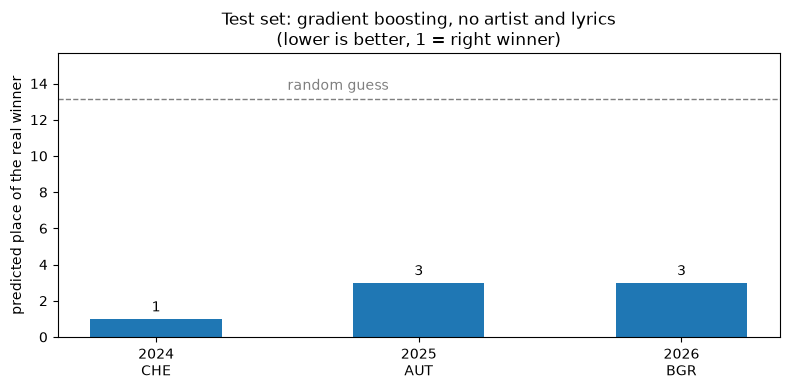

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
names = [f"{year}\n{board.loc[(board['year'] == year) & (board['real place'] == 1), 'to_iso3'].iloc[0]}" for year in TEST]
bars = ax.bar(names, [test_places[year] for year in TEST], color="tab:blue", width=0.5)
ax.bar_label(bars, padding=3)
ax.axhline(chance(test)["mean place"], color="tab:gray", linewidth=1, linestyle="--")
ax.text(0.5, chance(test)["mean place"] + 0.3, "random guess", color="tab:gray", ha="left", va="bottom")
ax.set_ylim(0, chance(test)["mean place"] + 2.5)
ax.set_ylabel("predicted place of the real winner")
ax.set_title(f"Test set: {best_name}\n(lower is better, 1 = right winner)")
plt.tight_layout()
plt.show()

### The predicted top N
The model's top N songs of every test final, so we see who it expected to win and where the real winner was. Blue is the predicted score, grey the real score, and the number at the end of each row is the song's real place. Change `N` to show more or fewer songs.

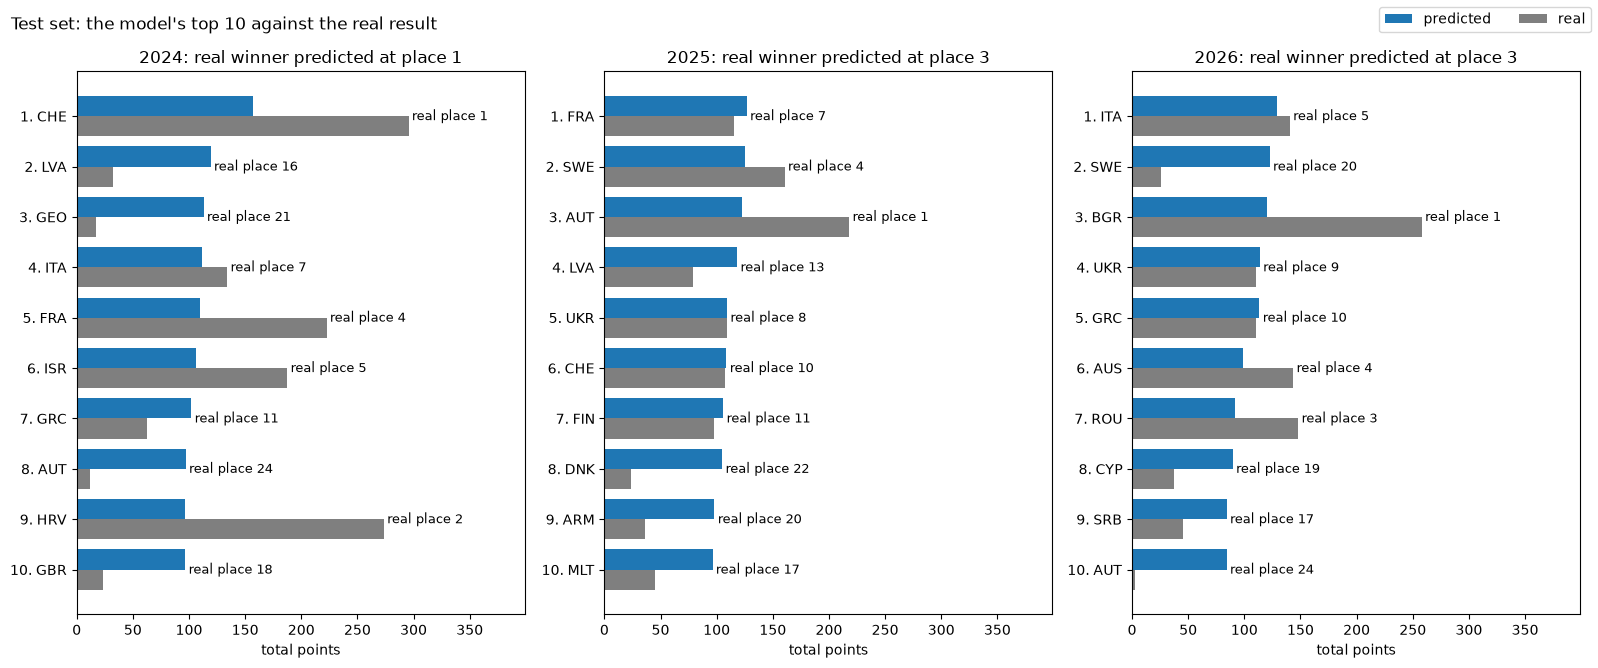

In [21]:
N = 10

fig, axes = plt.subplots(1, len(TEST), figsize=(16, 0.45 * N + 2.2))
for ax, year in zip(axes, TEST):
    songs = board[board["year"] == year].sort_values("predicted place").head(N)
    rows = np.arange(len(songs))
    ax.barh(rows - 0.2, songs["predicted"], height=0.4, color="tab:blue", label="predicted")
    ax.barh(rows + 0.2, songs["points"], height=0.4, color="tab:gray", label="real")
    for row, (_, song) in zip(rows, songs.iterrows()):
        ax.text(max(song["predicted"], song["points"]) + 3, row, f"real place {song['real place']}",
                va="center", fontsize=9)
    ax.set_yticks(rows, [f"{p}. {c}" for p, c in zip(songs["predicted place"], songs["to_iso3"])])
    ax.invert_yaxis()
    ax.set_xlim(0, board["points"].max() * 1.35)
    ax.set_xlabel("total points")
    ax.set_title(f"{year}: real winner predicted at place {test_places[year]}")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2)
fig.suptitle(f"Test set: the model's top {N} against the real result", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 9. Every final as a test year (leave one year out)

Three test finals are few, one surprising winner changes a lot. So every final from 2008 to 2026 is tested once:

1. Take one final out, this is the test year.
2. Train the best model (gradient boosting without artist and lyrics, same settings as above) on **all the other finals**.
3. Predict the left out final and see where the real winner ends up.

Missing values are filled with the median of the training finals of that round, never with the test year. In the end every final has one predicted place for its winner.

Two things to keep in mind:
- The training finals also include **later** years, so this is a check of the model, not a forecast made the day before.
- The settings were chosen on **2021–2023**, so those three years look a little better than they would on fresh data.

In [22]:
# X was filled with the medians of 2008-2019, start again from the raw values
raw = X.copy()
raw[NUMERIC] = df[NUMERIC].astype(float)
for column in YES_NO:
    raw[column] = df[column].map({True: 1, False: 0, "True": 1, "False": 0}).astype(float)

yearly = []
for year in sorted(df["year"].unique()):
    test_year = (df["year"] == year).to_numpy()
    others = ~test_year
    filled = raw.fillna(raw[others].median())[slim]
    model = HistGradientBoostingRegressor(max_iter=300, random_state=0, **boost_params)
    model.fit(filled[others], y[others])
    predicted = model.predict(filled[test_year])
    yearly.append({"year": year,
                   "set": "train" if year in TRAIN else "validation" if year in VAL else "test",
                   "real winner": df.loc[test_year].groupby("to_iso3")["points"].sum().idxmax(),
                   "winner predicted at": winner_rank(test_year, predicted)[year],
                   "chance": chance(test_year)["mean place"]})
yearly = pd.DataFrame(yearly)
print(yearly.round(1).to_string(index=False))

places = yearly["winner predicted at"]
print(f"\nover {len(yearly)} finals: winner on average at place {places.mean():.1f} "
      f"(chance {yearly['chance'].mean():.1f}), predicted first {(places == 1).sum()} times, "
      f"in the top 3 {(places <= 3).sum()} times")

# the same split by the set each final was in when the model and its settings were chosen
print("\nby set:")
for name in ["train", "validation", "test"]:
    part = yearly.loc[yearly["set"] == name, "winner predicted at"]
    print(f"\t{name:10s} {len(part):2d} finals, winner on average at place {part.mean():.1f}, "
          f"first {(part == 1).sum()}, top 3 {(part <= 3).sum()}")

 year        set real winner  winner predicted at  chance
 2008      train         RUS                    2    13.0
 2009      train         NOR                    4    13.0
 2010      train         DEU                   16    13.0
 2011      train         AZE                    4    13.0
 2012      train         SWE                    4    13.5
 2013      train         DNK                   13    13.5
 2014      train         AUT                    9    13.5
 2015      train         SWE                   12    14.0
 2016      train         UKR                    3    13.5
 2017      train         PRT                   16    13.5
 2018      train         ISR                    3    13.5
 2019      train         NLD                    6    13.5
 2021 validation         ITA                    1    13.5
 2022 validation         UKR                    1    13.0
 2023 validation         SWE                    1    13.5
 2024       test         CHE                    1    13.0
 2025       te

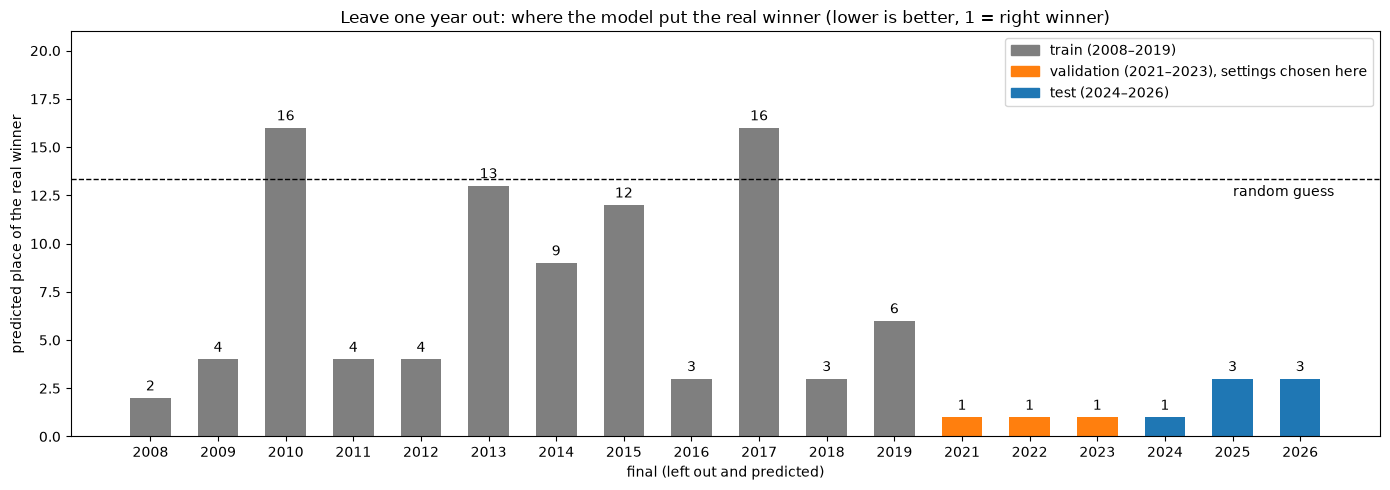

In [23]:
# colour = the set the final was in when the model and its settings were chosen
SET_COLORS = {"train": "tab:gray", "validation": "tab:orange", "test": "tab:blue"}

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(yearly["year"].astype(str), yearly["winner predicted at"],
              color=yearly["set"].map(SET_COLORS), width=0.6)
ax.bar_label(bars, padding=3)
ax.axhline(yearly["chance"].mean(), color="black", linewidth=1, linestyle="--")
ax.text(len(yearly) - 0.5, yearly["chance"].mean() - 0.3, "random guess", color="black",
        ha="right", va="top")
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in SET_COLORS.values()]
labels = ["train (2008–2019)", "validation (2021–2023), settings chosen here", "test (2024–2026)"]
ax.legend(handles, labels, loc="upper right")
ax.set_ylim(0, yearly["winner predicted at"].max() + 5)
ax.set_xlabel("final (left out and predicted)")
ax.set_ylabel("predicted place of the real winner")
ax.set_title("Leave one year out: where the model put the real winner (lower is better, 1 = right winner)")
plt.tight_layout()
plt.show()

## 10. Figures for the slides

Three figures, saved as PNG in `figures/` next to this notebook, with big fonts for the projector.

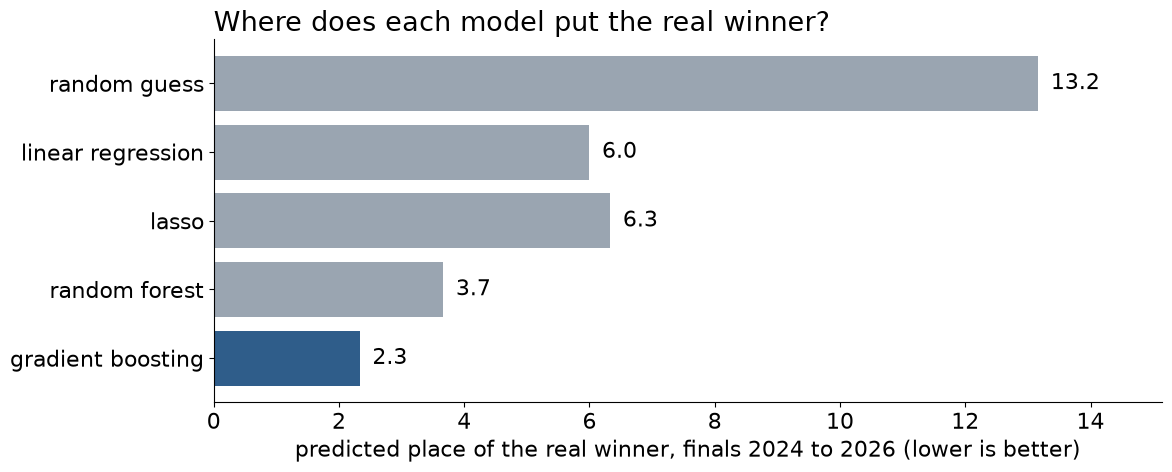

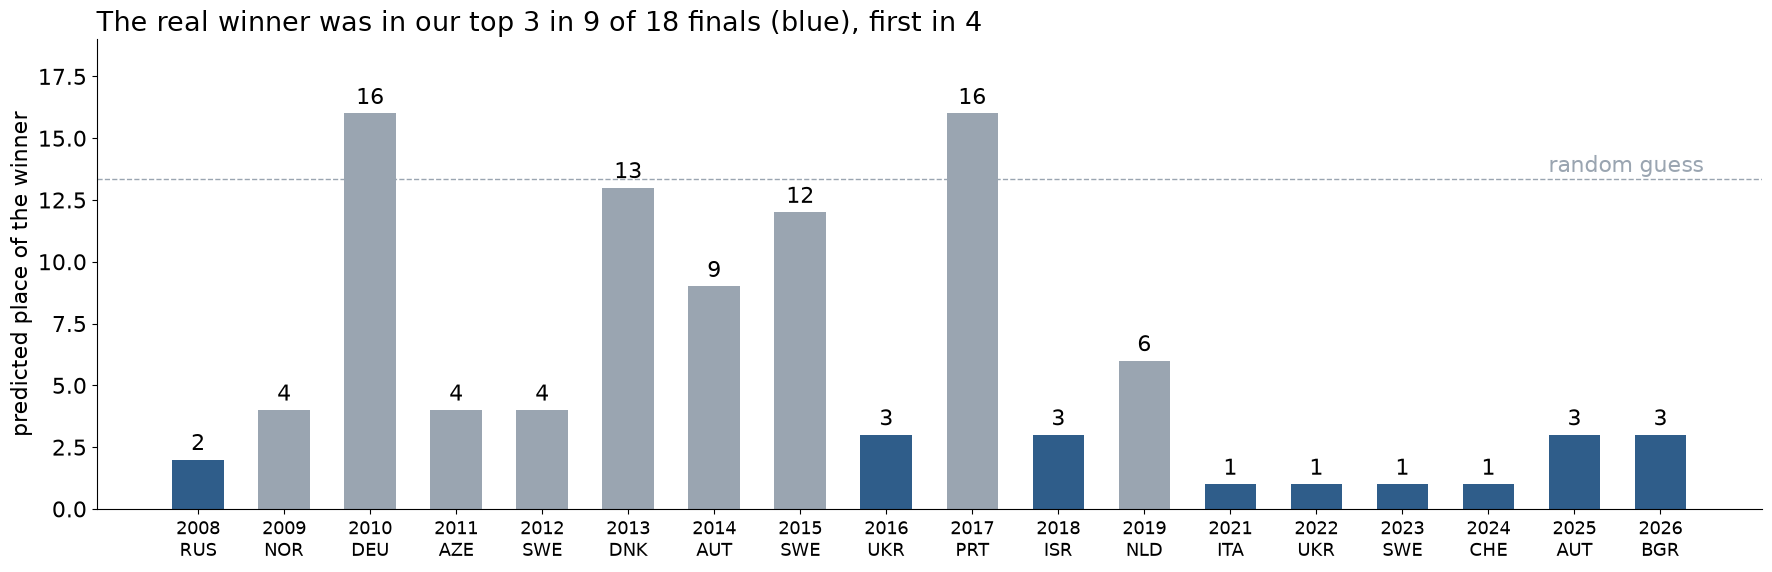

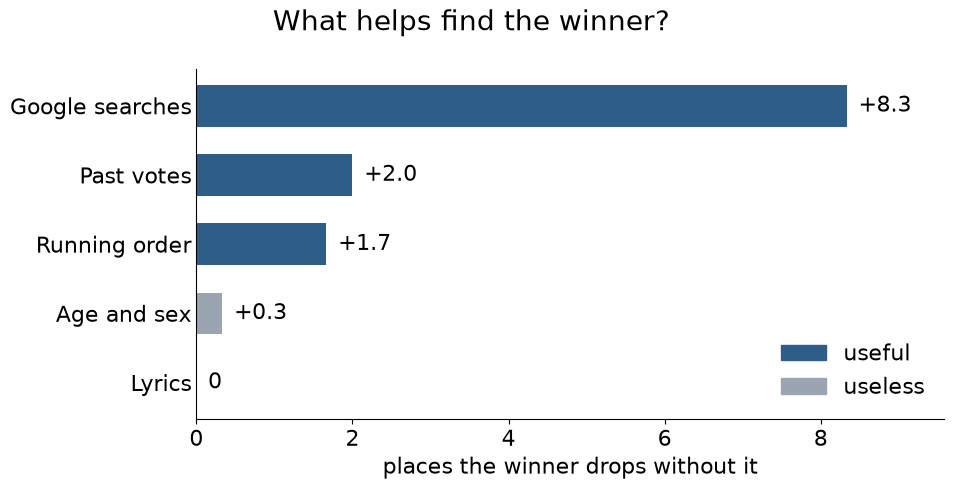

In [24]:
import os
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"font.size": 16, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY = "#2f5d8a", "#9aa5b1"

# slide 4: where does each model put the real winner, test finals 2024 to 2026
MODELS = {"linear regression": "linear regression", "lasso": "lasso",
          "random forest": "random forest",
          "gradient boosting": "gradient boosting, no artist and lyrics"}
winner_place = {label: winner_summary(winner_rank(test, best[name][0].predict(best[name][2])))["mean place"]
                for label, name in MODELS.items()}
winner_place["random guess"] = chance(test)["mean place"]
names = ["random guess", *MODELS]
# blue goes to the lowest number, whichever model that is (ties at one decimal share it)
lowest = round(min(winner_place[n] for n in MODELS), 1)
fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(names[::-1], [winner_place[n] for n in names[::-1]],
        color=[BLUE if n in MODELS and round(winner_place[n], 1) == lowest else GREY for n in names[::-1]])
for row, n in enumerate(names[::-1]):
    ax.text(winner_place[n] + 0.2, row, f"{winner_place[n]:.1f}", va="center")
ax.set_xlim(0, max(winner_place.values()) * 1.15)
ax.set_xlabel("predicted place of the real winner, finals 2024 to 2026 (lower is better)")
ax.set_title("Where does each model put the real winner?", loc="left")
fig.tight_layout()
fig.savefig("figures/slide-4-how-good.png", dpi=150)
plt.show()

# slide 5: every final, left out once and predicted by a model trained on all the others
fig, ax = plt.subplots(figsize=(18, 6))
labels = [f"{y}\n{w}" for y, w in zip(yearly["year"], yearly["real winner"])]
places = yearly["winner predicted at"]
bars = ax.bar(labels, places, color=[BLUE if p <= 3 else GREY for p in places], width=0.6)
ax.bar_label(bars, padding=3)
ax.axhline(yearly["chance"].mean(), color=GREY, linewidth=1, linestyle="--")
ax.text(len(yearly) - 0.5, yearly["chance"].mean() + 0.3, "random guess", color=GREY, ha="right")
ax.set_ylabel("predicted place of the winner")
ax.set_ylim(0, places.max() + 3)
ax.tick_params(axis="x", labelsize=13)
ax.set_title(f"The real winner was in our top 3 in {(places <= 3).sum()} of {len(yearly)} finals "
             f"(blue), first in {(places == 1).sum()}", loc="left")
fig.tight_layout()
fig.savefig("figures/slide-5-predicted-vs-real.png", dpi=150)
plt.show()

# slide 6: useful and useless features, from the validation check in section 7
SHORT = {
    "Google searches": "Google searches",
    "past points between the countries": "Past votes",
    "running order": "Running order",
    "age and sex": "Age and sex",
    "lyrics": "Lyrics",
}
everything = ablation.loc["nothing (all features)", "mean place"]
# how many places the real winner drops when the model does not get the group
drop = (ablation["mean place"].drop("nothing (all features)") - everything).rename(SHORT)
drop = drop.sort_values()
# useful = losing it costs the winner at least one place
useful = drop >= 1

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(drop.index, drop.values, color=[BLUE if u else GREY for u in useful], height=0.6)
for bar, value in zip(bars, drop.values):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height() / 2,
            f"+{value:.1f}" if value > 0 else "0", va="center")
ax.set_xlim(0, drop.max() * 1.15)
ax.set_xlabel("places the winner drops without it")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=GREY)],
          labels=["useful", "useless"], loc="lower right", frameon=False)
# the labels take the left side, so the plot starts later and ends later to keep the whole chart centred
fig.subplots_adjust(left=0.25, right=0.93, top=0.86, bottom=0.16)
fig.suptitle("What helps find the winner?", fontsize=20)
fig.savefig("figures/slide-6-what-helps.png", dpi=150)
plt.show()


## 11. Summary

### All columns of `features_full.csv`

| column | meaning | used? |
|---|---|---|
| `points` | points the voting country gave this song (0–12), from 2016 half of jury plus public | **target** |
| `year`, `entry_id`, `from_iso3`, `to_iso3` | which final, which song, who votes, who receives | no, identify the row |
| `vote_type` | jury, public or combined | no, gone after averaging jury and public |
| `log_dist` | logarithm of the distance between the two countries | yes |
| `dist`, `distw` | the same distance without the logarithm | no, duplicate of `log_dist` |
| `contig` | the two countries share a border | yes |
| `comlang_off` | they share an official language | yes |
| `comlang_ethno` | a language spoken by at least 9 % in both | yes |
| `colony`, `comcol`, `smctry` | colonial link, same former colonizer, once the same country | yes |
| `past_points` | average points this pair gave each other in earlier finals | yes |
| `past_meetings` | how many earlier finals this pair met in | yes |
| `web_interest` | Google web searches for the song in the voting country before the final (0–100) | yes |
| `youtube_interest` | the same for YouTube searches | yes |
| `censored` | both search values are 0, the search volume was too small to measure | yes |
| `running_position` | the song's place in the running order | yes |
| `artist_age` | age of the solo artist at the final (bands have none) | yes |
| `artist_sex` | female, male, other, or band/unknown | yes |
| `sentiment` | mood of the lyrics: neutral, sad, funny | yes |
| `theme` | theme of the lyrics: romance, heartbreak, society, … | yes |
| `repetition_verse`, `repetition_chorus` | the lyrics repeat a lot | yes |
| `receiver_effect`, `points_received_total`, `points_share` | computed from the points of this final | no, unknown before the final |
| `round`, `jury_share`, `televote_share`, `separately_reported`, `row_vote` | voting rules of the year, the same for every song of a final | no, cannot tell songs apart |

### Removed as useless (8 features)
Lasso set them to 0 **and** the forest uses them less than 1 %: a commonly spoken language (`comlang_ethno`), same former colonizer (`comcol`), the lyric themes society, kinship, festivity, the funny mood, and the "unknown" mood and theme (only 2010, which has no lyrics). Removing them did not bring the winners higher (forest: 1, 2, 1 → 1, 3, 1).

### Results: where the model puts the real winner

Validation finals 2021, 2022, 2023 (lower is better, 1 = the right winner):

| model | winner predicted at | average place |
|---|---|---|
| chance | | 13.3 |
| linear regression | 4 / 9 / 12 | 8.3 |
| lasso | 5 / 6 / 5 | 5.3 |
| random forest, all features | 1 / 2 / 1 | 1.3 |
| random forest, no artist and lyrics | 1 / 1 / 1 | 1.0 |
| **gradient boosting, no artist and lyrics** | **1 / 1 / 1** | **1.0** |

- **Best model: gradient boosting without the artist and lyric features** (learning rate 0.03, depth 3, at least 50 rows per leaf, 300 rounds). It ties with the forest on the validation winners and wins the tie because it predicts the votes better.
- **Test finals 2024–2026:** the real winners were predicted **1st** (Switzerland 2024), **3rd** (Austria 2025) and **3rd** (Bulgaria 2026), average place 2.3 against 13.2 for chance. Random forest 3.7, linear regression 6.0, lasso 6.3 (slide 4, section 12).
- **Honest note:** on validation the model got all three winners right, on test one of three. With three finals per set, a perfect validation score is partly luck, and choosing the settings on it overfits a little.
- **Every final as a test year** (section 9, leave one year out: each final predicted by the best model trained on all 17 other finals): the real winner was predicted **first in 4 of 18 finals** and **in the top 3 in 9 of 18**, on average at place 5.7 against 13.3 for chance. The big misses are Germany 2010 (16th, the year without Google data), Portugal 2017 (16th), Denmark 2013 (13th) and Sweden 2015 (12th). The best years are 2021–2024, but the settings were chosen on 2021–2023, so those look a little better than they would on fresh data. This is the most reliable number, because it uses all 18 finals.
- **What helps the winner:** Google searches most by far, then the past points between the countries and the running order. The years 2008–2015 help a lot. Age, sex and lyrics do not.

### For the slides (3 minutes in total, so about one sentence per slide)

- **Slide 4**, `figures/slide-4-how-good.png`: "On the finals 2024 to 2026 our best model put the real winner first, third and third. A random guess puts it in 13th."
- **Slide 5**, `figures/slide-5-predicted-vs-real.png`: "We tested every final from 2008 on its own, trained on all the others: the real winner was in our top 3 in 9 of 18 finals, and our first pick 4 times. A random guess puts it 13th."
- **Slide 6**, `figures/slide-6-what-helps.png`: "What finds the winner is Google searches before the final, then how countries voted for each other before and the running order. The artist's age and sex and the lyrics do not help."


## 12. Results for the report

Raw numbers for the figures of the technical report, written to `results/`. The test numbers of the models that were not chosen are computed here only for the report, nothing is chosen from them. The rank error (how many places a song is off on average) is added for the chosen model, to say how rough the whole scoreboard still is.

In [25]:
os.makedirs("results", exist_ok=True)


def rank_error(rows, predicted):
    """mean distance between predicted and real place, averaged over the finals"""
    board = df.loc[rows, ["year", "to_iso3", "points"]].assign(predicted=predicted)
    board = board.groupby(["year", "to_iso3"], as_index=False)[["points", "predicted"]].sum()
    errors = []
    for _, songs in board.groupby("year"):
        real = songs["points"].rank(ascending=False, method="min")
        guess = songs["predicted"].rank(ascending=False, method="min")
        errors.append((real - guess).abs().mean())
    return float(np.mean(errors))


def random_rank_error(rows, draws=1000, seed=0):
    """rank error of a random scoreboard: mean and 95 % range of the mean over the finals"""
    rng = np.random.default_rng(seed)
    board = df.loc[rows].groupby(["year", "to_iso3"], as_index=False)["points"].sum()
    per_final = []
    for _, songs in board.groupby("year"):
        real = songs["points"].rank(ascending=False, method="min").to_numpy()
        per_final.append([np.abs(real - rng.permutation(real)).mean() for _ in range(draws)])
    errors = np.mean(per_final, axis=0)
    return errors.mean(), np.percentile(errors, 2.5), np.percentile(errors, 97.5)


validation_inputs = {
    "linear regression": X_val_s, "lasso": X_val_s, "random forest": X_val,
    "random forest, fewer features": X_val[keep],
    "lasso, fewer features": scaler_small.transform(X_val[keep]),
    "random forest, no artist and lyrics": X_val[slim],
    "gradient boosting, no artist and lyrics": X_val[slim],
}
rows = []
for name, (model, X_tr, X_te) in best.items():
    X_va = validation_inputs[name]
    val_places = winner_rank(val, model.predict(X_va))
    test_predicted = model.predict(X_te)
    test_places = winner_rank(test, test_predicted)
    rows.append({"model": name, "chosen": name == best_name,
                 "val_r2": model.score(X_va, y_val), "test_r2": model.score(X_te, y_test),
                 "test_rank_error": rank_error(test, test_predicted),
                 **{f"val_{y}": p for y, p in val_places.items()},
                 **{f"test_{y}": p for y, p in test_places.items()}})
pd.DataFrame(rows).to_csv("results/models.csv", index=False)

mean, low, high = random_rank_error(test)
pd.DataFrame([{"set": name, "winner_place": chance(part)["mean place"], "right_winner": chance(part)["top 1"]}
              for name, part in [("validation", val), ("test", test)]]) \
    .assign(rank_error=[None, mean], low=[None, low], high=[None, high]) \
    .to_csv("results/chance.csv", index=False)
yearly.to_csv("results/yearly.csv", index=False)
ablation.reset_index().to_csv("results/ablation.csv", index=False)
print(pd.read_csv("results/models.csv").round(3).to_string(index=False))
print(pd.read_csv("results/chance.csv").round(3).to_string(index=False))

                                  model  chosen  val_r2  test_r2  test_rank_error  val_2021  val_2022  val_2023  test_2024  test_2025  test_2026
                      linear regression   False   0.065    0.172            5.931         4         9        12          4          7          7
                          random forest   False   0.155    0.074            6.199         1         2         1          1          2          8
                                  lasso   False   0.125    0.184            5.877         5         6         5          5          8          6
          random forest, fewer features   False   0.157    0.065            6.146         1         3         1          1          2          8
                  lasso, fewer features   False   0.125    0.184            5.877         5         6         5          5          8          6
    random forest, no artist and lyrics   False   0.183    0.142            6.016         1         1         1          1        